# 05 - Kalibrasi dan Threshold Bisnis

Model terpilih dari notebook 04 dimuat dari `artifacts/model.joblib`.
Semua langkah di notebook ini memakai **validation saja**
(Januari-Maret 2026). Test April-Juni 2026 tidak dibuka.

Biaya:
- paket terlambat tanpa kabar: Rp50.000;
- kabar "kemungkinan terlambat" yang ternyata keliru: Rp5.000.

In [1]:
from pathlib import Path
import json
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import siapkan_fitur

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BIAYA_TERLAMBAT_TANPA_KABAR = 50_000
BIAYA_KABAR_KELIRU = 5_000
TEORITIS = BIAYA_KABAR_KELIRU / (BIAYA_TERLAMBAT_TANPA_KABAR + BIAYA_KABAR_KELIRU)

model = joblib.load(ROOT / "artifacts" / "model.joblib")
metadata = json.loads((ROOT / "artifacts" / "metadata.json").read_text(encoding="utf-8"))

semua = pd.read_csv(ROOT / "data" / "clean.csv", parse_dates=["tanggal_pickup"])
valid = semua.loc[semua["tanggal_pickup"].between("2026-01-01", "2026-03-31")].copy()
del semua

assert valid["tanggal_pickup"].min() >= pd.Timestamp("2026-01-01")
assert valid["tanggal_pickup"].max() <= pd.Timestamp("2026-03-31")

X_valid = siapkan_fitur(valid, metadata)
y_valid = valid["terlambat"].to_numpy()
prob = model.predict_proba(X_valid)[:, 1]

print("Model        :", metadata["model_version"])
print("Baris valid  :", len(valid))
print("Rasio target :", round(y_valid.mean(), 4))
print("Threshold teoretis:", round(TEORITIS, 4))

Model        : engineered-lightgbm-v1
Baris valid  : 6623
Rasio target : 0.2188
Threshold teoretis: 0.0909


## 1. Cek kalibrasi

Brier score model dibandingkan dengan Brier score prevalensi (tebakan konstan).
Kurva reliabilitas memakai 10 kelompok probabilitas. Sebagai pembanding,
sigmoid/Platt dan isotonic diuji dengan 5-fold pada validation saja supaya
perbandingannya tidak memakai data yang sama untuk fit dan skor.

In [2]:
brier_model = brier_score_loss(y_valid, prob)
brier_prevalensi = brier_score_loss(y_valid, np.full_like(y_valid, y_valid.mean(), dtype=float))

kuantil = pd.qcut(prob, 10, duplicates="drop")
reliabilitas = pd.DataFrame({"prob": prob, "y": y_valid, "bin": kuantil})
reliabilitas = reliabilitas.groupby("bin", observed=True).agg(
    n=("y", "size"), prob_rata=("prob", "mean"), obs=("y", "mean")
)
reliabilitas["titik"] = reliabilitas.index.map(lambda x: (x.left + x.right) / 2)

brier_sigmoid = brier_score_loss(
    y_valid,
    CalibratedClassifierCV(model, method="sigmoid", cv=5).fit(X_valid, y_valid).predict_proba(X_valid)[:, 1],
)
brier_isotonik = brier_score_loss(
    y_valid,
    CalibratedClassifierCV(model, method="isotonic", cv=5).fit(X_valid, y_valid).predict_proba(X_valid)[:, 1],
)

print(f"Brier model       : {brier_model:.4f}")
print(f"Brier prevalensi  : {brier_prevalensi:.4f}")
print(f"Brier sigmoid/5f  : {brier_sigmoid:.4f}")
print(f"Brier isotonic/5f : {brier_isotonik:.4f}")
print(f"Rata-rata prob.   : {prob.mean():.4f}")
print(f"Rata-rata target  : {y_valid.mean():.4f}")

Brier model       : 0.1544
Brier prevalensi  : 0.1709
Brier sigmoid/5f  : 0.1709
Brier isotonic/5f : 0.1468
Rata-rata prob.   : 0.1765
Rata-rata target  : 0.2188


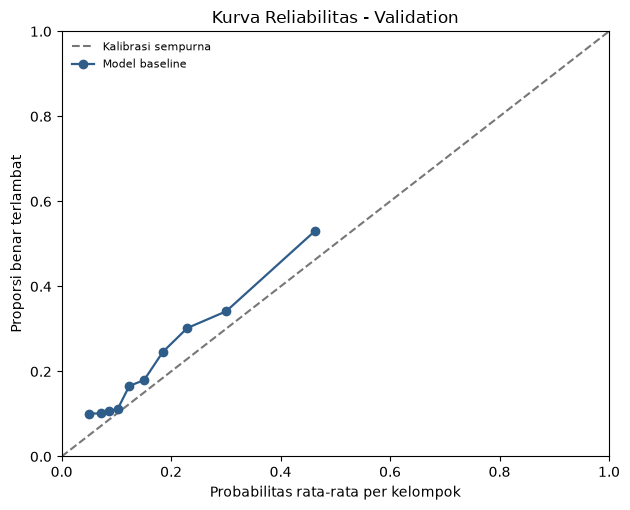

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.plot([0, 1], [0, 1], linestyle="--", color="#777777", label="Kalibrasi sempurna")
ax.plot(reliabilitas["prob_rata"], reliabilitas["obs"], marker="o", color="#2f5d8a",
        linewidth=1.6, label="Model baseline")
ax.set_title("Kurva Reliabilitas - Validation")
ax.set_xlabel("Probabilitas rata-rata per kelompok")
ax.set_ylabel("Proporsi benar terlambat")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_reliabilitas.png", dpi=160, bbox_inches="tight")
plt.show()

Kalibrasi dipakai hanya jika penurunan Brier minimal 0,005. Jika dipakai,
kalibrator ikut disimpan bersama model agar API memakai probabilitas yang sama
dengan perhitungan threshold. Jika tidak, model tetap sederhana.

In [4]:
perbaikan_sigmoid = brier_model - brier_sigmoid
perbaikan_isotonik = brier_model - brier_isotonik
pakai_kalibrasi = max(perbaikan_sigmoid, perbaikan_isotonik) >= 0.005

if pakai_kalibrasi:
    metode = "isotonic" if perbaikan_isotonik >= perbaikan_sigmoid else "sigmoid"
    model_kalibrasi = CalibratedClassifierCV(model, method=metode, cv=5).fit(X_valid, y_valid)
    prob = model_kalibrasi.predict_proba(X_valid)[:, 1]
    brier_setelah = brier_score_loss(y_valid, prob)
    # Simpan model terkalibrasi supaya API memakai probabilitas yang sama.
    joblib.dump(model_kalibrasi, ROOT / "artifacts" / "model.joblib")
    metadata["model_version"] = metadata["model_version"] + "-" + metode
    metadata["calibration_applied"] = metode
    print(f"Kalibrasi dipakai: {metode}. Brier {brier_model:.4f} -> {brier_setelah:.4f}")
else:
    metode = "tidak ada"
    brier_setelah = brier_model
    metadata["calibration_applied"] = metode
    print(
        f"Kalibrasi tidak dipakai. Perbaikan terbaik hanya {max(perbaikan_sigmoid, perbaikan_isotonik):.4f}, "
        "di bawah batas 0,005."
    )

Kalibrasi dipakai: isotonic. Brier 0.1544 -> 0.1468


## 2. Threshold empiris berdasarkan biaya

Untuk setiap threshold, paket dikabari bila probabilitasnya lebih besar atau
sama dengan threshold. Total biaya dihitung dari kasus terlambat tanpa kabar dan
kabar keliru. Threshold dengan biaya minimum dipilih; jika ada ikatan, nilai
tertinggi dipilih agar jumlah kabar berkurang.

In [5]:
def hitung_biaya(threshold: float) -> int:
    dikabari = prob >= threshold
    terlambat_tanpa_kabar = int(((y_valid == 1) & ~dikabari).sum())
    kabar_keliru = int(((y_valid == 0) & dikabari).sum())
    return (
        terlambat_tanpa_kabar * BIAYA_TERLAMBAT_TANPA_KABAR
        + kabar_keliru * BIAYA_KABAR_KELIRU
    )


grid_threshold = np.linspace(0, 1, 1001)
biaya = np.array([hitung_biaya(t) for t in grid_threshold])
biaya_min = biaya.min()
yang_minimum = np.flatnonzero(np.isclose(biaya, biaya_min))
indeks_terbaik = int(yang_minimum[-1])
threshold_empiris = round(float(grid_threshold[indeks_terbaik]), 3)
biaya_teoretis = hitung_biaya(TEORITIS)

print(f"Threshold empiris : {threshold_empiris:.3f}")
print(f"Biaya minimum     : Rp{biaya_min:,.0f}")
print(f"Biaya teoretis    : Rp{biaya_teoretis:,.0f}")
print(f"Penghematan       : Rp{biaya_teoretis - biaya_min:,.0f}")

Threshold empiris : 0.205
Biaya minimum     : Rp18,540,000
Biaya teoretis    : Rp25,870,000
Penghematan       : Rp7,330,000


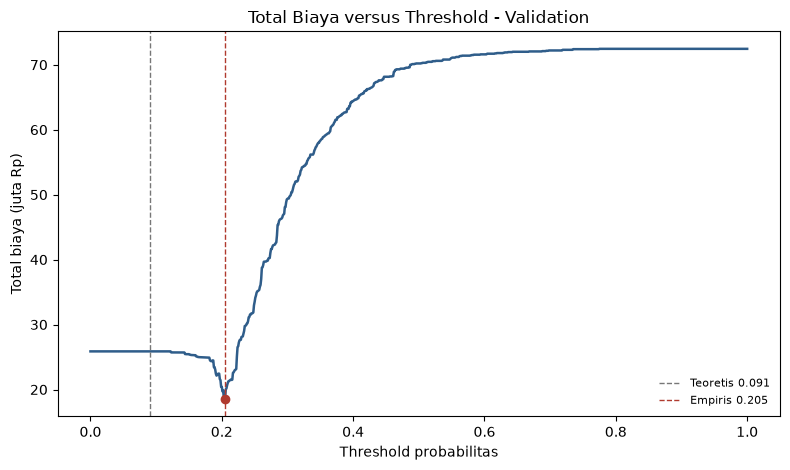

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(grid_threshold, biaya / 1_000_000, color="#2f5d8a", linewidth=1.8)
ax.axvline(TEORITIS, color="#777777", linestyle="--", linewidth=1,
           label=f"Teoretis {TEORITIS:.3f}")
ax.axvline(threshold_empiris, color="#b03a2e", linestyle="--", linewidth=1,
           label=f"Empiris {threshold_empiris:.3f}")
ax.scatter([threshold_empiris], [biaya_min / 1_000_000], color="#b03a2e", zorder=3)
ax.set_title("Total Biaya versus Threshold - Validation")
ax.set_xlabel("Threshold probabilitas")
ax.set_ylabel("Total biaya (juta Rp)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_biaya_vs_threshold.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Perbandingan strategi

Strategi dibandingkan pada data validation yang sama.

In [7]:
def rincian(threshold: float) -> dict:
    dikabari = prob >= threshold
    return {
        "terlambat_tanpa_kabar": int(((y_valid == 1) & ~dikabari).sum()),
        "kabar_keliru": int(((y_valid == 0) & dikabari).sum()),
        "jumlah_dikabari": int(dikabari.sum()),
    }


baris_strategi = []
for nama, threshold in [
    ("Tidak mengabari siapa pun", 1.01),
    ("Mengabari semua", 0.0),
    (f"Threshold teoretis {TEORITIS:.3f}", TEORITIS),
    (f"Threshold empiris {threshold_empiris:.3f}", threshold_empiris),
]:
    rinciannya = rincian(threshold)
    total = hitung_biaya(threshold)
    baris_strategi.append(
        {
            "strategi": nama,
            "total_biaya": total,
            "biaya_per_paket": round(total / len(y_valid)),
            "jumlah_dikabari": rinciannya["jumlah_dikabari"],
            "terlambat_tanpa_kabar": rinciannya["terlambat_tanpa_kabar"],
            "kabar_keliru": rinciannya["kabar_keliru"],
        }
    )

tabel_strategi = pd.DataFrame(baris_strategi)
tabel_strategi

,strategi,total_biaya,biaya_per_paket,jumlah_dikabari,terlambat_tanpa_kabar,kabar_keliru
0,Tidak mengabari siapa pun,72450000,10939,0,1449,0
1,Mengabari semua,25870000,3906,6623,0,5174
2,Threshold teoretis 0.091,25870000,3906,6623,0,5174
3,Threshold empiris 0.205,18540000,2799,2352,255,1158


## 4. Batas `prioritaskan`

Prioritas adalah tindakan lebih mahal untuk sebagian paket, jadi zona ini dibuat
lebih kecil daripada zona "kabari". Aturan data: ambil threshold terendah di atas
threshold empiris yang memberi precision minimal 0,70 dan mencakup minimal 100
paket validation. Artinya lebih dari dua pertiga paket di zona itu benar-benar
terlambat, tetapi jumlahnya masih cukup untuk ditindaklanjuti.

In [8]:
MIN_PRECISION = 0.70
MIN_PAKET = max(100, int(0.01 * len(y_valid)))
grid_prioritas = np.arange(threshold_empiris + 0.005, 0.901, 0.005)

threshold_prioritas = None
for t in grid_prioritas:
    dikabari = prob >= t
    jumlah = int(dikabari.sum())
    if jumlah < MIN_PAKET:
        continue
    presisi = float(((y_valid == 1) & dikabari).sum() / jumlah)
    if presisi >= MIN_PRECISION:
        threshold_prioritas = round(float(t), 3)
        break

if threshold_prioritas is None:
    threshold_prioritas = 0.50
threshold_prioritas = round(float(threshold_prioritas), 3)

rincian_prioritas = rincian(threshold_prioritas)
presisi_prioritas = ((y_valid == 1) & (prob >= threshold_prioritas)).sum() / rincian_prioritas["jumlah_dikabari"]

print(f"Threshold prioritaskan: {threshold_prioritas:.3f}")
print(f"Presisi zona prioritas: {presisi_prioritas:.4f}")
print(f"Jumlah paket prioritas: {rincian_prioritas['jumlah_dikabari']}")
print(f"Syarat minimal        : precision {MIN_PRECISION}, paket {MIN_PAKET}")

Threshold prioritaskan: 0.240
Presisi zona prioritas: 0.7389
Jumlah paket prioritas: 1176
Syarat minimal        : precision 0.7, paket 100


## Kunci threshold

Threshold final ditulis ke `artifacts/thresholds.json` dan juga ke
`artifacts/metadata.json` supaya API dan Streamlit memakai nilai yang sama.
Test tetap tidak dipakai.

In [9]:
waktu_kunci = pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S")
config_path = ROOT / "artifacts" / "thresholds.json"

config = {
    "model_version": metadata["model_version"],
    "model_terpilih": metadata["tipe_model"],
    "sumber_data": "validation 2026-01-01 sampai 2026-03-31",
    "tanggal_kunci": waktu_kunci,
    "kalibrasi": {
        "metode": metode,
        "brier_sebelum": float(brier_model),
        "brier_prevalensi": float(brier_prevalensi),
        "brier_sigmoid_cv5": float(brier_sigmoid),
        "brier_isotonik_cv5": float(brier_isotonik),
    },
    "thresholds": {
        "kabari_pelanggan": threshold_empiris,
        "prioritaskan": threshold_prioritas,
    },
    "alasan": {
        "kabari_pelanggan": (
            f"Biaya minimum validation Rp{biaya_min:,.0f}; teoretis {TEORITIS:.4f} "
            f"memberi biaya Rp{biaya_teoretis:,.0f}."
        ),
        "prioritaskan": (
            f"Precision {presisi_prioritas:.3f} dengan {rincian_prioritas['jumlah_dikabari']} paket, "
            f"memenuhi syarat precision >= {MIN_PRECISION} dan paket >= {MIN_PAKET}."
        ),
    },
    "biaya": {
        "terlambat_tanpa_kabar": BIAYA_TERLAMBAT_TANPA_KABAR,
        "kabar_keliru": BIAYA_KABAR_KELIRU,
        "teoretis": TEORITIS,
        "minimum_validation": int(biaya_min),
    },
    "test_disentuh": False,
}

config_path.write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

metadata["thresholds"] = config["thresholds"]
metadata["threshold_config"] = "artifacts/thresholds.json"
metadata["threshold_status"] = "final; dikunci dari validation"
metadata["calibration"] = config["kalibrasi"]
metadata["test_disentuh"] = False
metadata["metrics"]["validation"]["threshold_kabari"] = threshold_empiris
metadata["metrics"]["validation"]["threshold_prioritaskan"] = threshold_prioritas
metadata["metrics"]["validation"]["biaya_minimum"] = int(biaya_min)
(ROOT / "artifacts" / "metadata.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8"
)

print("Tersimpan:", config_path)
print("kabari_pelanggan:", threshold_empiris)
print("prioritaskan   :", threshold_prioritas)
print("Metadata diperbarui dengan threshold final.")

Tersimpan: C:\PROJECTVibeCoding\ModelMLStudyCase8\artifacts\thresholds.json
kabari_pelanggan: 0.205
prioritaskan   : 0.24
Metadata diperbarui dengan threshold final.


Data test April-Juni 2026 belum dibuka, diprediksi, atau dievaluasi. Threshold
sudah dikunci sebelum tahap test.